In [2]:
import pandas as pd

df = pd.read_csv("../data/netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
print(df.shape)
df.info()
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

(8807, 12)
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64
Dupli

In [4]:
# Duplicates hatao
df = df.drop_duplicates()

# Kuch rows mein duration galti se rating column mein hai, usse theek karo
mask = df['duration'].isna() & df['rating'].astype(str).str.contains('min', na=False)
df.loc[mask, 'duration'] = df.loc[mask, 'rating']
df.loc[mask, 'rating'] = 'Unknown'

# Missing values bharo
for col in ['director', 'cast', 'country', 'rating']:
    df[col] = df[col].fillna('Unknown')

# Date column
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month_name()

# Duration: number aur unit alag karo (Movie = min, TV Show = Seasons)
df['duration_num'] = df['duration'].str.extract(r'(\d+)')[0].astype(float)
df['duration_unit'] = df['duration'].str.extract(r'([A-Za-z]+)')[0]

df.isnull().sum()

show_id           0
type              0
title             0
director          0
cast              0
country           0
date_added       10
release_year      0
rating            0
duration          0
listed_in         0
description       0
year_added       10
month_added      10
duration_num      0
duration_unit     0
dtype: int64

In [5]:
# Ek cell mein kai countries/genres comma se likhi hain, unhe alag rows mein todte hain
countries = df[['show_id', 'country']].copy()
countries['country'] = countries['country'].str.split(',')
countries = countries.explode('country')
countries['country'] = countries['country'].str.strip()
countries = countries[countries['country'] != '']

genres = df[['show_id', 'listed_in']].copy()
genres['genre'] = genres['listed_in'].str.split(',')
genres = genres.explode('genre')
genres['genre'] = genres['genre'].str.strip()
genres = genres[['show_id', 'genre']]

print(countries.shape, genres.shape)

(10843, 2) (19323, 2)


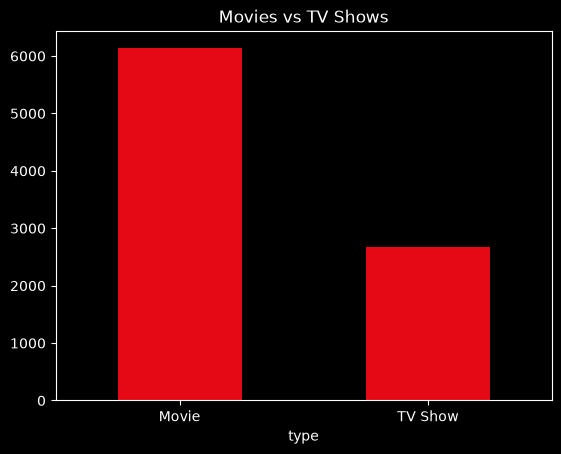

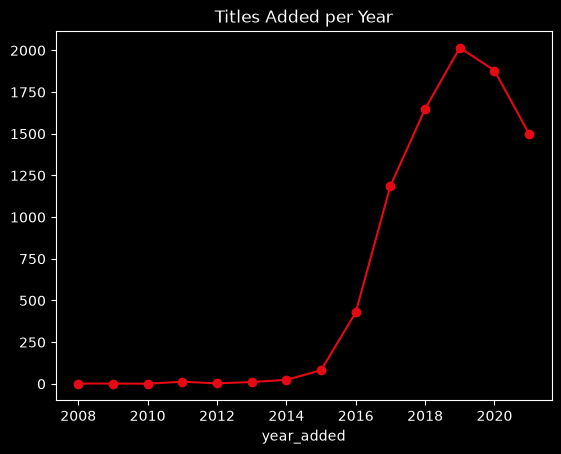

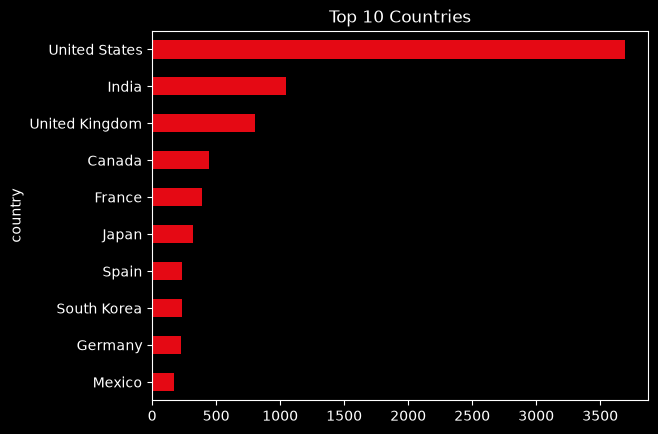

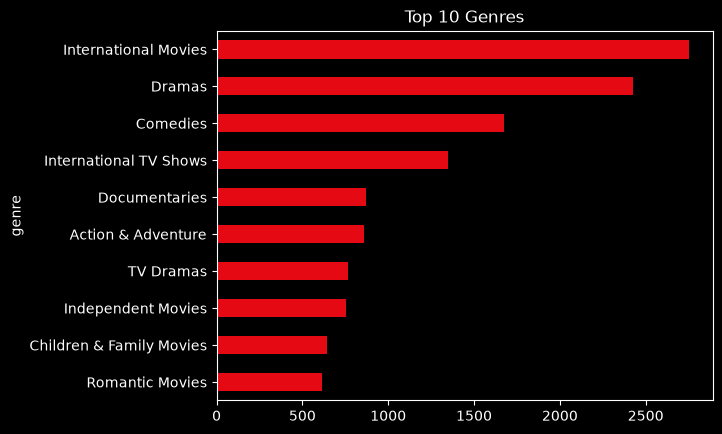

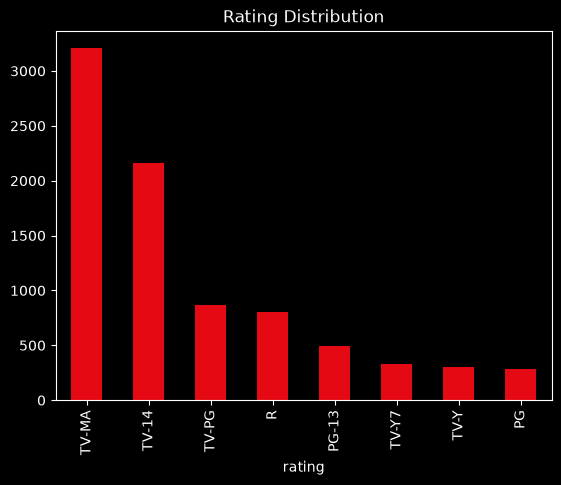

In [6]:
import matplotlib.pyplot as plt
RED = '#E50914'
plt.style.use('dark_background')

# 1. Movies vs TV Shows
df['type'].value_counts().plot(kind='bar', color=RED)
plt.title('Movies vs TV Shows'); plt.xticks(rotation=0)
plt.savefig('../images/type_count.png', bbox_inches='tight'); plt.show()

# 2. Titles added per year
df['year_added'].value_counts().sort_index().plot(kind='line', color=RED, marker='o')
plt.title('Titles Added per Year')
plt.savefig('../images/titles_per_year.png', bbox_inches='tight'); plt.show()

# 3. Top 10 countries
c = countries[countries['country'] != 'Unknown']['country'].value_counts().head(10)
c.sort_values().plot(kind='barh', color=RED)
plt.title('Top 10 Countries')
plt.savefig('../images/top_countries.png', bbox_inches='tight'); plt.show()

# 4. Top 10 genres
g = genres['genre'].value_counts().head(10)
g.sort_values().plot(kind='barh', color=RED)
plt.title('Top 10 Genres')
plt.savefig('../images/top_genres.png', bbox_inches='tight'); plt.show()

# 5. Rating distribution
df[df['rating'] != 'Unknown']['rating'].value_counts().head(8).plot(kind='bar', color=RED)
plt.title('Rating Distribution')
plt.savefig('../images/ratings.png', bbox_inches='tight'); plt.show()

In [7]:
print("Total titles:", len(df))
print("Movies %:", round((df['type'] == 'Movie').mean() * 100, 1))
print("Top country:", countries[countries['country'] != 'Unknown']['country'].value_counts().idxmax())
print("Top genre:", genres['genre'].value_counts().idxmax())
print("Peak year for adding titles:", int(df['year_added'].value_counts().idxmax()))
print("Most common rating:", df[df['rating'] != 'Unknown']['rating'].value_counts().idxmax())
print("Avg movie duration (min):", round(df[df['type'] == 'Movie']['duration_num'].mean(), 1))

Total titles: 8807
Movies %: 69.6
Top country: United States
Top genre: International Movies
Peak year for adding titles: 2019
Most common rating: TV-MA
Avg movie duration (min): 99.6


In [8]:
df.to_csv('../data/netflix_clean.csv', index=False)
countries.to_csv('../data/netflix_countries.csv', index=False)
genres.to_csv('../data/netflix_genres.csv', index=False)
print("Saved!")

Saved!


In [1]:
import pandas as pd

d = pd.read_csv("../data/netflix_clean.csv")
d['year_added'] = d['year_added'].astype('Int64')
d.to_csv("../data/netflix_clean.csv", index=False)
print(d['year_added'].head())

0    2021
1    2021
2    2021
3    2021
4    2021
Name: year_added, dtype: Int64
